In [43]:
# 그래프 관련
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np

# 머신러닝 관련
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.metrics import mean_absolute_error 
from sklearn.linear_model import LogisticRegression
from scipy.special import expit
from scipy.special import softmax

In [44]:
# LogisticRegression 이진분류 -> 다중분류

fish = pd.read_csv('data/fish_logistic.csv')
fish.head(2)

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.0200
1,Bream,290.0,26.3,31.2,12.48,4.3056


In [45]:
# fish['Species'].unique()    # ['Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt']
data = fish[fish.columns[1:]].values
label = fish['Species'].values

In [46]:
# 학습데이터 / 테스트 데이터 분리
train_data,test_data,train_label,test_label = train_test_split(data,label)
train_data[:2]

array([[ 19.9   ,  15.    ,  16.2   ,   2.9322,   1.8792],
       [500.    ,  31.5   ,  36.4   ,  13.7592,   4.368 ]])

In [47]:
# StandartScaler
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [55]:
# 다중 분류
# C 매개변수 : alpha, C 규제 - 높아지면 완화 / 낮아지면 강화 
# max_iter : 반복 자동화하는 매개변수

train_score = []
test_score = []
cc = [0.001,0.01,0.1,1,10,20,50,100]
for c in cc:
    lr = LogisticRegression(C=c,max_iter=1000)
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled, train_label))
    test_score.append(lr.score(test_scaled, test_label))

# lr = LogisticRegression(C=20,max_iter=1000)
# lr.fit(train_scaled, train_label)

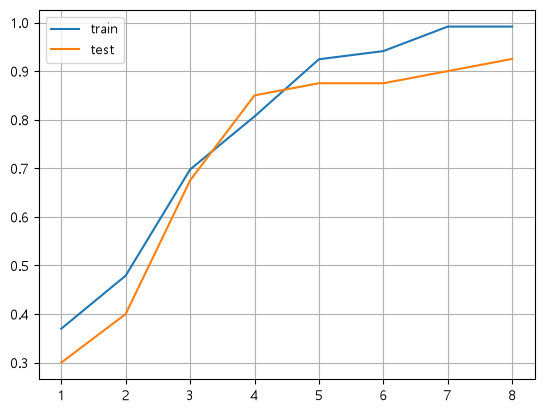

In [57]:
list1 = [1,2,3,4,5,6,7,8]
plt.plot(list1, train_score)
plt.plot(list1, test_score)
plt.legend(['train','test'])
plt.grid()
plt.show()


In [ ]:
# # expit 이진분류 : 0과 1로 만들어줌
# lr.predict_proba(test_scaled[:5])
# decisions = lr.decision_function(test_scaled[:5])

# # softmax 다중분류 : 0과 1숫자로 변환 확률 표현
# soft1 = softmax(decisions,axis=1) #axis=1은 행방향
# np.round(soft1, decimals=3)
# print('train 정확도: ', lr.score(train_scaled, train_label))
# print('test 정확도: ', lr.score(test_scaled, test_label))

train 정확도:  0.9327731092436975
test 정확도:  0.925


In [ ]:
# 사용자 입력 받기 (예: 720,35,40.6,16.3618,6.09)
# input_str = input('생선의 무게,길이,대각선,높이,넓이 입력: ')
# input_data = [[float(x) for x in input_str.split(',')]]

# in_data = '242.0,25.4,30.0,11.52,4.0200'
# in_data = '55,14.7,16.5,6.8475,2.3265'
# in_data = '32,13.7,14.7,3.528,1.9992'
in_data = '300,35,38.8,5.9364,4.3844'
input_data = [[float(x) for x in in_data.split(',')]]

# 훈련 때 사용한 ss(StandardScaler)로 반드시 스케일링
input_scaled = ss.transform(input_data)

# 예측 클래스 및 확률 계산
pred_species = lr.predict(input_scaled)[0]          # 예측된 생선 이름 (예: 'Bream')
pred_proba = lr.predict_proba(input_scaled)[0]      # 각 클래스별 확률 배열 (예: [0.9976, 0.0024])

# 가장 높은 확률(예측된 생선의 확률) 추출 후 백분율 변환
max_proba = np.max(pred_proba) * 100

print(f'분류생선확률 : {pred_species} ({max_proba:.2f}%)')

분류생선확률 : Pike (91.77%)
